# WIP

# Flagging proteins in control samples

# Imports

In [32]:
import os
from tqdm import tqdm
import numpy as np
import pandas as pd
from pathlib import Path
import anndata
import seaborn as sns
from matplotlib import pyplot as plt

from SCI_py.data.subset import get_proteins_by_condition

tqdm.pandas()

# 0. Path Configuration

In [2]:
NOTEBOOK_DIR = Path().resolve()
ROOT_OUT      = NOTEBOOK_DIR / "../../Data"
ROOT_OUT      = ROOT_OUT.resolve()
ROOT_OUT.mkdir(parents=True, exist_ok=True)

# Allow user override via environment variable
ROOT_OUT = Path(os.environ.get("SCI_DATA_DIR", ROOT_OUT))

ROOT_OUT.mkdir(parents=True, exist_ok=True)
print(f"Output directory: {ROOT_OUT}")

FIGURES_OUT = NOTEBOOK_DIR / "../../Figures"
FIGURES_OUT = FIGURES_OUT.resolve()
FIGURES_OUT.mkdir(parents=True, exist_ok=True)

# Overwrite with environment variable
FIGURES_OUT = Path(os.environ.get("SCI_FIGURES_DIR", FIGURES_OUT))
print(f"Figures directory: {FIGURES_OUT}")

ANNDATA_IN = os.path.join(
    ROOT_OUT,
    'AnnData',
    'base'
)

Output directory: /home/sam/SCI/SCI/Data
Figures directory: /home/sam/SCI/SCI/Figures


In [3]:
SHOW_FIGURES = False

# 1. Load Data

In [4]:
adata_precursor = anndata.io.read_h5ad(
    os.path.join(ANNDATA_IN, 'adata_precursor.h5ad')
)
adata_protein = anndata.io.read_h5ad(
    os.path.join(ANNDATA_IN, 'adata_protein.h5ad')
)

adata_precursor_qc = anndata.io.read_h5ad(
    os.path.join(ANNDATA_IN, 'adata_precursor_qc.h5ad')
)
adata_protein_qc = anndata.io.read_h5ad(
    os.path.join(ANNDATA_IN, 'adata_protein_qc.h5ad')
)

In [5]:
adata_precursor

AnnData object with n_obs × n_vars = 3114 × 72061
    obs: 'sample_name', 'plate_id', 'plate_idx', 'source name', 'comment[X position]', 'comment[Y position]', 'comment[Plate Number]', 'comment[Gradient time]', 'comment[thawing timepoint]', 'comment[plate arrival]', 'injection_order', 'institute_name', 'Reinjection', 'Diameter', 'Elongation', 'Circularity', 'Doublet', 'Dividing', 'Dying', 'CellInBlank', 'comment[plate arrival]_date', 'comment[plate arrival]_time', 'comment[plate arrival]_datetime', 'comment[Gradient time]_date', 'comment[Gradient time]_time', 'comment[Gradient time]_datetime', 'instrument_type'
    var: 'PG.ProteinGroups', 'PG.ProteinAccessions', 'PEP.StrippedSequence', 'PEP.IsProteotypic', 'EG.ModifiedSequence', 'FG.Charge', 'FG.LabeledSequence', 'PG.Pvalue', 'PG.Qvalue', 'FG.Qvalue', 'EG.GlobalPrecursorQvalue', 'PG.Cscore', 'EG.ApexRT', 'EG.RTPredicted', 'EG.iRTEmpirical', 'EG.iRTPredicted', 'FG.PrecWindowNumber', 'FG.CScore', 'Contaminant'
    layers: 'EG.ApexRT', '

In [6]:
adata_protein

AnnData object with n_obs × n_vars = 3114 × 7231
    obs: 'sample_name', 'plate_id', 'plate_idx', 'source name', 'comment[X position]', 'comment[Y position]', 'comment[Plate Number]', 'comment[Gradient time]', 'comment[thawing timepoint]', 'comment[plate arrival]', 'injection_order', 'institute_name', 'Reinjection', 'Diameter', 'Elongation', 'Circularity', 'Doublet', 'Dividing', 'Dying', 'CellInBlank', 'comment[plate arrival]_date', 'comment[plate arrival]_time', 'comment[plate arrival]_datetime', 'comment[Gradient time]_date', 'comment[Gradient time]_time', 'comment[Gradient time]_datetime', 'instrument_type'
    var: 'PG.ProteinAccessions', 'PEP.StrippedSequence', 'PEP.IsProteotypic', 'EG.ModifiedSequence', 'FG.Charge', 'FG.LabeledSequence', 'FG.PrecursorIon', 'PG.Pvalue', 'PG.Qvalue', 'FG.Qvalue', 'EG.GlobalPrecursorQvalue', 'PG.Cscore', 'EG.ApexRT', 'EG.RTPredicted', 'EG.iRTEmpirical', 'EG.iRTPredicted', 'FG.PrecWindowNumber', 'FG.CScore', 'Contaminant'
    layers: 'PG.Cscore', 'PG

# 2. Identity of Proteins in Control Conditions

Control wells on each SCI plate serve distinct purposes: isolating biological signal from sample preparation artefacts, instrument background, and cross-contamination. The helper `get_proteins_by_condition` queries each control type and returns, for each lab, the protein accessions detected in at least one well of that condition. From this per-lab table, the most frequently recurring accessions are extracted.

**Why this matters** — proteins consistently identified in negative-control wells constrain the interpretable proteome of the single-cell samples. Any protein recurring in blank or control wells may reflect carry-over, ambient contamination, or reagent impurities rather than genuine cellular signal. The per-lab breakdown further distinguishes whether contamination is instrument- or site-specific — suggesting a local fluidic or column issue — from contamination universal across labs, which would point to a shared reagent or protocol artefact.wn also flags whether contamination is instrument-specific (suggesting a fluidic or column issue) or universal across labs (suggesting a reagent or protocol artefact).

The four control types analysed below differ in their content and position in the experimental workflow:

| Control | Content | Purpose |
|---|---|---|
| **`CellenONE blank`** | 0.1% formic acid | Monitors injection carry-over; centrally prepared and affected by shipment |
| **`Site-specific blank`** | 0.1% formic acid | Monitors carry-over with correction for signal variability introduced by shipment and freeze-thaw cycling |
| **`Processing control`** | MasterMix, rehydration and quenching solvents; no cell | Quantifies reagent background independent of cell material |
| **`Sorting control`** | `Processing control` + one cellenONE dispensing droplet; no cell | Captures cell dispensing background, including potential extracellular or lysis material from the cell suspension |

In [11]:
from SCI_py.constants.maps import LABS

def get_proteins_by_condition(
    adata,
    source_name: list,
    pct: bool = False
    
) -> pd.DataFrame:
    """
    For each protein, compute the number and percentage of samples
    in which it is detected, broken down by lab and condition.

    Parameters
    ----------
    adata:
        AnnData object with ``plate_idx`` and ``source name`` in obs,
        ``Contaminant`` and ``PG.ProteinAccessions`` in var.
    source_name:
        Source names to include.

    Returns
    -------
    pd.DataFrame
        MultiIndex columns (lab, condition) with detection percentage,
        indexed by protein accession.
    """
    adata_selection = adata[
        adata.obs['source name'].isin(source_name),
        ~adata.var['Contaminant']
    ]

    protein_accessions = adata_selection.var['PG.ProteinAccessions']
    records            = {}

    for lab in LABS:
        for condition in source_name:
            mask = (
                (adata_selection.obs['plate_idx']    == lab) &
                (adata_selection.obs['source name']  == condition)
            )
            idx = adata_selection.obs[mask].index
            if len(idx) == 0:
                continue

            X          = adata_selection[idx, :].X
            n_samples  = X.shape[0]
            n_detected = np.sum(~np.isnan(X), axis=0)

            records[(lab, condition)] = pd.Series(
                np.array(n_detected).flatten(),
                index = protein_accessions,
                name  = (lab, condition),
            )
            if pct:
                records[(lab, condition)] = records[(lab, condition)] / n_samples * 100

    df = pd.DataFrame(records)
    df.columns = pd.MultiIndex.from_tuples(df.columns, names=['lab', 'condition'])

    # drop proteins never detected across all lab/condition combinations
    df = df.loc[df.max(axis=1) > 0]

    return df.sort_index()

### 2.1. CellenONE Blank

Wells containing only 0.1% formic acid, centrally prepared alongside the single-cell samples and therefore subject to the same shipment and freeze-thaw history. Proteins identified here most likely originate from injection carry-over or cross-contamination between adjacent wells due to plate handling. Because these blanks were prepared and sealed centrally, any signal they carry reflects the state of the plate at the time of shipment rather than site-specific handling. The frequency distribution indicates how many labs detect the same protein: a protein found across all labs is likely a ubiquitous background contaminant, whereas one found at a single site suggests a lab-specific source such as a contaminated column or specific plate handling issues.

In [25]:
condition = 'Cellenone blank'

blank_cellenone_counts = get_proteins_by_condition(
    adata_protein,
    source_name=[condition],
    pct=False
)
n_total = blank_cellenone_counts.sum(axis=1)
n_labs = (blank_cellenone_counts!=0).sum(axis=1)

n_proteins_per_lab = (blank_cellenone_counts!=0).sum(axis=0)
blank_cellenone_counts[('n_total', condition)] = n_total
blank_cellenone_counts[('n_labs', condition)] = n_labs

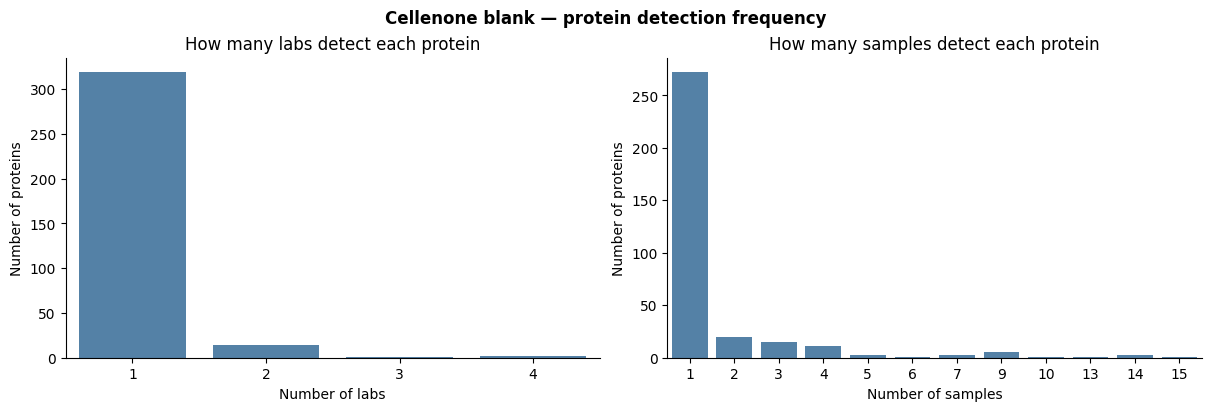

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)

# n_labs
counts_labs = blank_cellenone_counts[('n_labs', 'Cellenone blank')].value_counts().sort_index()
sns.barplot(x=counts_labs.index, y=counts_labs.values, ax=axes[0], color='steelblue')
axes[0].set(
    xlabel = 'Number of labs',
    ylabel = 'Number of proteins',
    title  = 'How many labs detect each protein',
)
axes[0].spines[['top', 'right']].set_visible(False)

# n_total
counts_total = blank_cellenone_counts[('n_total', 'Cellenone blank')].value_counts().sort_index()
sns.barplot(x=counts_total.index, y=counts_total.values, ax=axes[1], color='steelblue')
axes[1].set(
    xlabel = 'Number of samples',
    ylabel = 'Number of proteins',
    title  = 'How many samples detect each protein',
)
axes[1].spines[['top', 'right']].set_visible(False)

fig.suptitle('Cellenone blank — protein detection frequency', fontweight='bold')
plt.show()

### 2.2. Site-specific Blank

Blank wells appended by each participating laboratory upon receipt of the plate, also containing only 0.1% formic acid. Unlike the cellenONE blanks, these wells were never frozen or shipped, making them insensitive to freeze-thaw and transit artefacts. Proteins detected here can therefore be attributed to local sources — environmental keratins, reagent impurities, or handling contamination specific to a given site. Overlap with the cellenONE blanks is expected for carry-over contaminants shared across conditions; proteins unique to the site-specific blanks are more likely to reflect local laboratory environment and handling.

In [8]:
site_specific_blanks = get_proteins_by_condition(
    adata_protein,
    source_name=['Site specific blanks']
)

print(site_specific_blanks.melt().dropna().value_counts('value').value_counts())

print('\nMost occuring proteins: ')
print(site_specific_blanks.melt().dropna().value_counts('value').head(15).index.tolist())

Astral_1: 7 proteins detected in blanks
Astral_2: 797 proteins detected in blanks
Astral_3: 17 proteins detected in blanks
Astral_4: 41 proteins detected in blanks
Astral_5: 1340 proteins detected in blanks
Astral_6: 29 proteins detected in blanks
timsTOF_1: 7 proteins detected in blanks
timsTOF_2: 22 proteins detected in blanks
timsTOF_3: 28 proteins detected in blanks
count
1    966
2    634
3     18
Name: count, dtype: int64

Most occuring proteins: 
['Q562R1', 'Q15843', 'Q16718', 'P62979', 'P62826', 'P62857', 'P62318', 'P06899', 'P23528', 'P63261', 'Q9HCM7', 'P09104', 'P0C0S5;Q71UI9', 'Q8TF72', 'P35030']


### 2.3. Processing Control

Wells containing MasterMix, rehydration buffer and quenching solvent in the same volumes used for single-cell samples, but without a cell. These wells capture the full reagent background of the sample preparation workflow. Identifications here are expected to overlap substantially with the blank controls, and may additionally include trypsin autolysis products or other protease-derived peptides introduced during digestion. Proteins identified in the processing control that also appear as biologically relevant hits in downstream single-cell analysis should be interpreted with caution and will be flagged accordingly.

In [9]:
processing_control = get_proteins_by_condition(
    adata_protein,
    source_name=['Processing control']
)

print(processing_control.melt().dropna().value_counts('value').value_counts())

print('\nMost occuring proteins: ')
print(processing_control.melt().dropna().value_counts('value').head(15).index.tolist())

Astral_1: 73 proteins detected in blanks
Astral_2: 266 proteins detected in blanks
Astral_3: 377 proteins detected in blanks
Astral_4: 680 proteins detected in blanks
Astral_5: 35 proteins detected in blanks
Astral_6: 1368 proteins detected in blanks
timsTOF_1: 280 proteins detected in blanks
timsTOF_2: 565 proteins detected in blanks
timsTOF_3: 2664 proteins detected in blanks
count
1    2122
2     788
3     238
4     113
5      79
6      61
7      52
8      32
9       7
Name: count, dtype: int64

Most occuring proteins: 
['P01040', 'P25311', 'P07477', 'P31944', 'P61626', 'P35030', 'P05109', 'P22735', 'P47929', 'Q5T749', 'Q15828', 'P01857', 'P04083', 'P62979', 'Q08188']


### 2.4. Sorting Control

Wells receiving the same reagent content as the processing control, with the addition of one dispensing droplet from the cellenONE sorting medium but without a cell. Proteins detected here that are absent from the processing control and blanks are candidates for extracellular material or intracellular content released by lysed or dead cells into the suspension prior to isolation. This fraction represents biological background inherent to the cell suspension rather than to the isolated cell itself. As with the processing control, any such proteins that emerge as hits in single-cell analysis will be flagged, as they cannot be unambiguously attributed to the single isolated cell.

In [10]:
sorting_control = get_proteins_by_condition(
    adata_protein,
    source_name=['Sorting control']
)

print(sorting_control.melt().dropna().value_counts('value').value_counts())

print('\nMost occuring proteins: ')
print(sorting_control.melt().dropna().value_counts('value').head(15).index.tolist())

Astral_1: 2319 proteins detected in blanks
Astral_2: 3720 proteins detected in blanks
Astral_3: 417 proteins detected in blanks
Astral_4: 880 proteins detected in blanks
Astral_5: 994 proteins detected in blanks
Astral_6: 1169 proteins detected in blanks
timsTOF_1: 80 proteins detected in blanks
timsTOF_2: 673 proteins detected in blanks
timsTOF_3: 1553 proteins detected in blanks
count
1    1877
2     960
3     612
4     420
5     301
6     170
8     130
7     117
9      12
Name: count, dtype: int64

Most occuring proteins: 
['P81605', 'P01040', 'P07339', 'P07477', 'P22735', 'P10599', 'Q13867', 'P62979', 'P31944', 'P61626', 'P35030', 'Q96P63', 'P62851', 'A8K2U0', 'P50995']
